| **Inicio**         | **atrás 1**                          | **Siguiente 3**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./5_1_ODE.ipynb) | [⏩](./5_3_Sistemas_lineales.ipynb) |

# 1. ¿Qué es un sistema dinámico?

Un sistema dinámico describe cómo cambia un estado con el tiempo.

Para una variable:

$$
\boxed{\frac{dx}{dt}=f(x)}
$$

Para varias variables:

$$
\boxed{
\frac{d\mathbf{x}}{dt}
=
\mathbf{f}(\mathbf{x})
}
$$

Por ejemplo, con dos variables:

$$
\begin{cases}
\dot{x}=f(x,y)\\
\dot{y}=g(x,y)
\end{cases}
$$

El punto

$$
(x,y)
$$

representa el **estado del sistema**.

Mientras pasa el tiempo, ese punto se mueve:

$$
(x(t),y(t)).
$$

Esa trayectoria es una **órbita** o **trajectory**.

# 2. Ejemplo real: población

Consideremos

$$
\frac{dP}{dt}
=
rP\left(1-\frac{P}{K}\right).
$$

Tenemos:

* $(P)$: población.
* $(r)$: tasa de crecimiento.
* $(K)$: capacidad de carga.

Supongamos:

$$
r=1,\qquad K=1000.
$$

Entonces:

$$
\dot P=P\left(1-\frac{P}{1000}\right).
$$

La pregunta de sistemas dinámicos ya no es simplemente resolver $P(t)$.

Queremos saber:

* ¿Dónde se estabiliza la población?
* ¿Qué pasa si empieza cerca de cero?
* ¿Qué pasa si empieza por encima de $(K)$?
* ¿Existen estados estables?
* ¿Qué ocurre si cambiamos $(r)$ o $(K)$?

Esto nos lleva al **equilibrio**.

# 3. Equilibrio

Un equilibrio es un estado que **no cambia con el tiempo**.

Para:

$$
\dot{x}=f(x)
$$

un equilibrio $(x^*)$ satisface:

$$
\boxed{f(x^*)=0}
$$

porque:

$$
\dot{x}=0.
$$

# 4. Ejemplo: logística

Tenemos:

$$
\dot P=P\left(1-\frac P K\right).
$$

Buscamos:

$$
P\left(1-\frac PK\right)=0.
$$

Por tanto:

$$
P=0
$$

o

$$
1-\frac PK=0.
$$

Entonces:

$$
\boxed{P=K}
$$

Los dos equilibrios son:

$$
\boxed{P_1^*=0}
$$

y

$$
\boxed{P_2^*=K}.
$$

# 5. Interpretación física

### Equilibrio $(P=0)$

Si no existe población:

$$
P(t)=0
$$

permanece allí.

 Equilibrio $(P=K)$

Si:

$$
P(t)=K
$$

entonces:

$$
\dot P=0.
$$

La población permanece en $(K)$.

Pero aquí aparece una pregunta mucho más interesante:

> ¿Qué pasa si perturbamos ligeramente el equilibrio?

Eso es **estabilidad**.

# 6. Estabilidad

Supongamos que tenemos:

$$
\dot{x}=f(x).
$$

Un equilibrio es estable si pequeñas perturbaciones no hacen que el sistema se aleje significativamente.

Intuitivamente:

### Estable

$$
\boxed{\text{perturbación}\rightarrow\text{regreso}}
$$

### Inestable

$$
\boxed{\text{perturbación}\rightarrow\text{alejamiento}}
$$

# 7. Ejemplo muy importante

Consideremos:

$$
\boxed{\dot{x}=x(1-x)}
$$

Los equilibrios:

$$
x=0
$$

y

$$
x=1.
$$

Podemos estudiar el signo de:

$$
f(x)=x(1-x).
$$

Para:

$$
x<0
$$

tenemos:

$$
f(x)<0.
$$

Para:

$$
0<x<1
$$

tenemos:

$$
f(x)>0.
$$

Para:

$$
x>1
$$

tenemos:

$$
f(x)<0.
$$

Entonces:

$$
\boxed{x=0\text{ es inestable}}
$$

porque las trayectorias se alejan.

Mientras:

$$
\boxed{x=1\text{ es estable}}
$$

porque las trayectorias cercanas regresan hacia $(1)$.

# 8. Phase line

Para sistemas de una dimensión podemos dibujar una **phase line**.

$$
\dot{x}=x(1-x)
$$

tiene:

```text
       x < 0        0        0 < x < 1       1        x > 1

         ←          ○           →             ●          ←
```

Donde:

* ○ = equilibrio inestable.
* ● = equilibrio estable.
* flechas = dirección del movimiento.

Esta idea será fundamental cuando pasemos a sistemas de dos dimensiones.

# 9. Python: phase line + soluciones

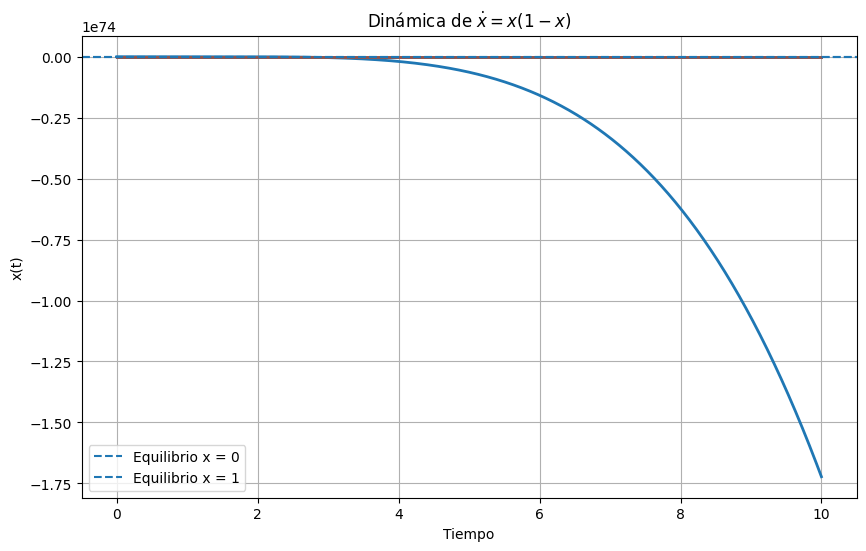

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def f(t, x):
    return x * (1 - x)

t = np.linspace(0, 10, 1000)

initial_conditions = [
    -0.5,
    0.2,
    0.5,
    0.8,
    1.2,
    2.0
]

plt.figure(figsize=(10, 6))

for x0 in initial_conditions:

    sol = solve_ivp(
        f,
        (0, 10),
        [x0],
        dense_output=True
    )

    x = sol.sol(t)[0]

    plt.plot(t, x, linewidth=2)

plt.axhline(
    0,
    linestyle="--",
    label="Equilibrio x = 0"
)

plt.axhline(
    1,
    linestyle="--",
    label="Equilibrio x = 1"
)

plt.xlabel("Tiempo")
plt.ylabel("x(t)")
plt.title(r"Dinámica de $\dot{x}=x(1-x)$")

plt.grid(True)
plt.legend()

plt.show()

Observa cómo:

$$
x=1
$$

atrae las soluciones.

# 10. Estabilidad mediante derivadas

Para una ODE:

$$
\dot{x}=f(x)
$$

podemos estudiar un equilibrio $(x^*)$ usando:

$$
\boxed{f'(x^*)}
$$

Si:

$$
f'(x^*)<0
$$

el equilibrio es localmente estable.

Si:

$$
f'(x^*)>0
$$

es inestable.

Si:

$$
f'(x^*)=0
$$

el criterio lineal **no decide** y necesitamos analizar términos de orden superior.

Esto último será especialmente importante en bifurcaciones.


# 11. Ejemplo más difícil

Consideremos:

$$
\boxed{
\dot{x}=x^3-4x
}
$$

Factorizamos:

$$
\dot{x}=x(x-2)(x+2).
$$

Los equilibrios son:

$$
\boxed{x^*=-2,0,2}
$$

Ahora:

$$
f'(x)=3x^2-4.
$$

Evaluamos:

### En $(x=-2)$

$$
f'(-2)=8>0
$$

inestable.

### En $(x=0)$

$$
f'(0)=-4<0
$$

estable.

### En $(x=2)$

$$
f'(2)=8>0
$$

inestable.

Tenemos entonces:

$$
\boxed{-2\text{ inestable},\quad 0\text{ estable},\quad 2\text{ inestable}}
$$

# 12. Sistemas de dos dimensiones

Ahora viene una de las partes más importantes de SciML.

Consideremos:

$$
\boxed{
\begin{cases}
\dot{x}=f(x,y)\\
\dot{y}=g(x,y)
\end{cases}
}
$$

Por ejemplo:

$$
\boxed{
\begin{cases}
\dot{x}=x(1-x-y)\\
\dot{y}=y(2-x-y)
\end{cases}
}
$$

Esto puede representar una interacción entre dos poblaciones.

# 13. Equilibrios de un sistema

Un equilibrio satisface simultáneamente:

$$
\dot{x}=0
$$

y

$$
\dot{y}=0.
$$

Es decir:

$$
f(x,y)=0
$$

$$
g(x,y)=0.
$$

Geométricamente, los equilibrios están donde se cruzan:

$$
\boxed{\text{nullcline}_x}
$$

y

$$
\boxed{\text{nullcline}_y}.
$$

# 14. Nullclines

Para:

$$
\dot{x}=f(x,y)
$$

la nullcline de $(x)$ es:

$$
\boxed{f(x,y)=0}.
$$

Sobre esa curva:

$$
\dot{x}=0.
$$

Análogamente:

$$
g(x,y)=0
$$

es la nullcline de $(y)$.

Los equilibrios son las intersecciones.

# 15. Jacobiano

Para analizar estabilidad de sistemas multidimensionales necesitamos el **Jacobiano**.

Para:

$$
\begin{cases}
\dot{x}=f(x,y)\\
\dot{y}=g(x,y)
\end{cases}
$$

el Jacobiano es:

$$
\boxed{
J=
\begin{pmatrix}
f_x & f_y\\
g_x & g_y
\end{pmatrix}
}
$$

Evaluamos:

$$
J(x^*,y^*).
$$

Después calculamos sus eigenvalues:

$$
\boxed{\lambda_1,\lambda_2}
$$

# 16. Clasificación mediante eigenvalues

Para un sistema 2D:

### Ambos negativos

$$
\lambda_1<0,\qquad\lambda_2<0
$$

→ **stable node**.

### Ambos positivos

$$
\lambda_1>0,\qquad\lambda_2>0
$$

→ **unstable node**.

### Uno positivo y otro negativo

$$
\lambda_1\lambda_2<0
$$

→ **saddle point**.

### Complejos con parte real negativa

$$
\lambda=\alpha\pm i\beta
$$

con:

$$
\alpha<0
$$

→ **stable spiral**.

### Complejos con parte real positiva

$$
\alpha>0
$$

→ **unstable spiral**.

# 17. Phase portraits

Un **phase portrait** representa:

$$
(x,y)
$$

en vez de:

$$
(x(t),y(t)).
$$

Cada solución es una trayectoria en el espacio de estados.

Para:

$$
\begin{cases}
\dot{x}=f(x,y)\\
\dot{y}=g(x,y)
\end{cases}
$$

dibujamos el campo:

$$
(f(x,y),g(x,y)).
$$

Cada flecha nos dice:

> "Si el sistema está aquí, ¿hacia dónde se moverá?"

# 18. Ejemplo difícil: sistema depredador-presa

Tomemos:

$$
\dot{x}=\alpha x-\beta xy
$$

$$
\dot{y}=\delta xy-\gamma y.
$$

Con:

$$
\alpha=1.5
$$

$$
\beta=1
$$

$$
\delta=0.75
$$

$$
\gamma=1.
$$

# 19. Equilibrios

La primera ecuación:

$$
x(\alpha-\beta y)=0.
$$

Por tanto:

$$
x=0
$$

o

$$
y=\frac{\alpha}{\beta}.
$$

La segunda:

$$
y(\delta x-\gamma)=0.
$$

Por tanto:

$$
y=0
$$

o

$$
x=\frac{\gamma}{\delta}.
$$

Entonces tenemos:

$$
\boxed{(0,0)}
$$

y:

$$
\boxed{
\left(
\frac{\gamma}{\delta},
\frac{\alpha}{\beta}
\right)
}
$$

que en nuestro caso es:

$$
\boxed{(4/3,1.5)}.
$$

# 20. Jacobiano del sistema

Tenemos:

$$
f=\alpha x-\beta xy
$$

$$
g=\delta xy-\gamma y.
$$

Entonces:

$$
J=
\begin{pmatrix}
\alpha-\beta y & -\beta x\\
\delta y & \delta x-\gamma
\end{pmatrix}.
$$

En el equilibrio:

$$
\left(\frac{\gamma}{\delta},
\frac{\alpha}{\beta}\right)
$$

obtenemos eigenvalues puramente imaginarios para el modelo ideal de Lotka-Volterra.

Eso explica las órbitas cerradas que veremos

# 21. Phase portrait en Python

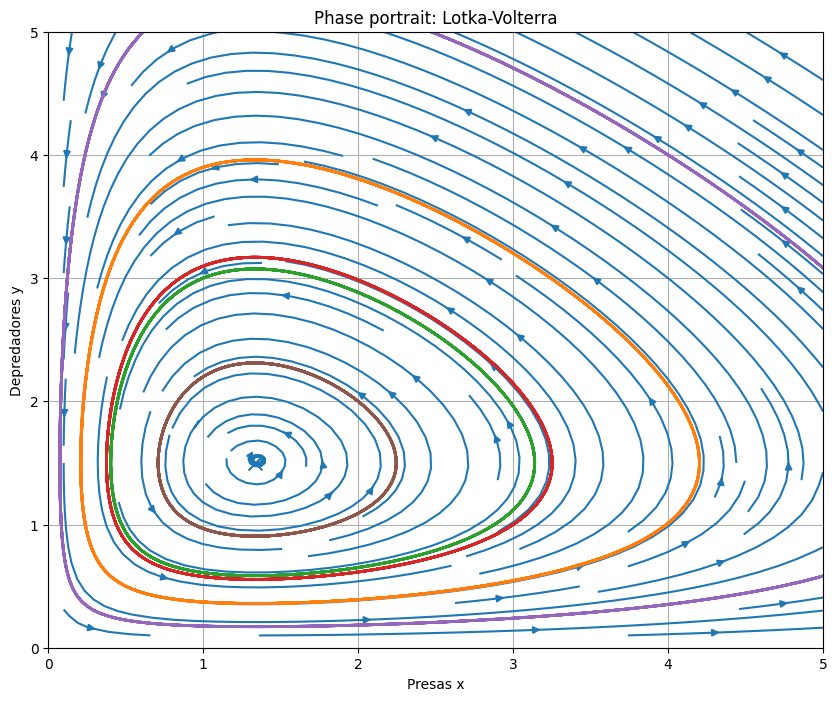

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

alpha = 1.5
beta = 1.0
delta = 0.75
gamma = 1.0

def system(t, z):

    x, y = z

    dx = alpha*x - beta*x*y
    dy = delta*x*y - gamma*y

    return [dx, dy]

x = np.linspace(0.1, 5, 30)
y = np.linspace(0.1, 5, 30)

X, Y = np.meshgrid(x, y)

U = alpha*X - beta*X*Y
V = delta*X*Y - gamma*Y

speed = np.sqrt(U**2 + V**2)

U = U / (speed + 1e-9)
V = V / (speed + 1e-9)

plt.figure(figsize=(10, 8))

plt.streamplot(
    X,
    Y,
    U,
    V,
    density=1.2
)

initial_conditions = [
    [0.5, 0.5],
    [1, 3],
    [3, 1],
    [4, 4],
    [2, 2]
]

for z0 in initial_conditions:

    sol = solve_ivp(
        system,
        (0, 30),
        z0,
        dense_output=True,
        max_step=0.02
    )

    t = np.linspace(0, 30, 2000)

    trajectory = sol.sol(t)

    plt.plot(
        trajectory[0],
        trajectory[1],
        linewidth=2
    )

plt.scatter(
    4/3,
    1.5,
    s=100,
    marker="x"
)

plt.xlabel("Presas x")
plt.ylabel("Depredadores y")

plt.title("Phase portrait: Lotka-Volterra")

plt.xlim(0, 5)
plt.ylim(0, 5)

plt.grid(True)

plt.show()

Aquí ya estás haciendo una gráfica fundamental de sistemas dinámicos.

# 22. ¿Qué significa físicamente el phase portrait?

Imagina que no conocemos el tiempo.

Simplemente observamos el estado:

$$
(x,y).
$$

Una trayectoria cerrada significa que:

1. aumenta la población de presas;
2. aumentan los depredadores;
3. disminuyen las presas;
4. disminuyen los depredadores;
5. vuelven a aumentar las presas.

Y el ciclo continúa.

Esto es un comportamiento dinámico.

# 23. Sistemas dinámicos: más allá del equilibrio

Un sistema dinámico puede tener diferentes comportamientos:

$$
\boxed{
\text{equilibrio}
}
$$

$$
\boxed{
\text{órbitas periódicas}
}
$$

$$
\boxed{
\text{quasi-periodicidad}
}
$$

$$
\boxed{
\text{caos}
}
$$

$$
\boxed{
\text{divergencia}
}
$$

Por eso los sistemas dinámicos son mucho más ricos que simplemente "resolver una ODE".

# 24. Bifurcaciones

Ahora llegamos a uno de los conceptos más importantes.

Una **bifurcación** ocurre cuando un pequeño cambio en un parámetro produce un **cambio cualitativo** en la dinámica.

Supongamos:

$$
\boxed{
\dot{x}=\mu-x^2
}
$$

donde:

$$
\mu
$$

es un parámetro.

# 25. Equilibrios de la bifurcación Saddle-Node

Tenemos:

$$
0=\mu-x^2.
$$

Entonces:

$$
x^2=\mu.
$$

Por tanto:

$$
x=\pm\sqrt{\mu}.
$$

Si:

$$
\mu>0
$$

existen dos equilibrios.

Si:

$$
\mu=0
$$

existe uno.

Si:

$$
\mu<0
$$

no existe ninguno.

Esto es una:

$$
\boxed{\text{Saddle-Node Bifurcation}}
$$

# 26. Diagrama de bifurcación

Podemos dibujar:

$$
x^*=\pm\sqrt{\mu}.
$$

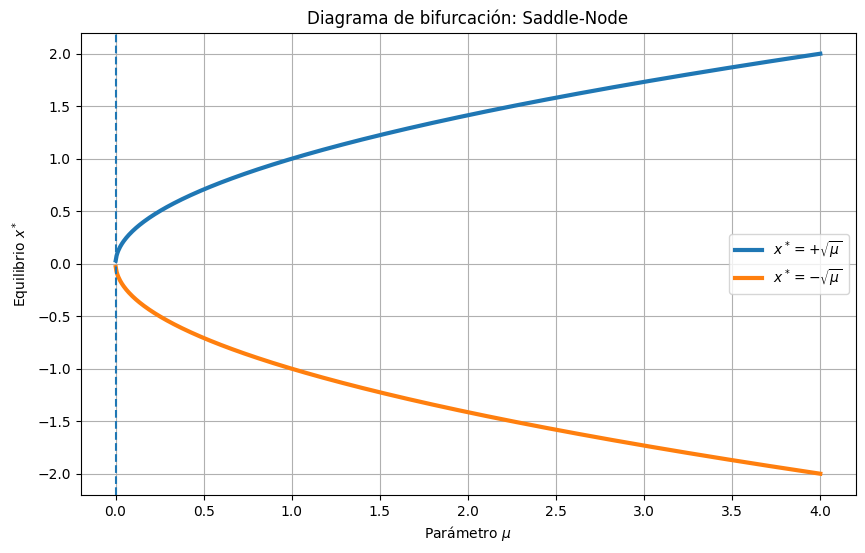

In [3]:
import numpy as np
import matplotlib.pyplot as plt

mu = np.linspace(-1, 4, 1000)

positive = np.where(mu >= 0, np.sqrt(np.maximum(mu, 0)), np.nan)
negative = np.where(mu >= 0, -np.sqrt(np.maximum(mu, 0)), np.nan)

plt.figure(figsize=(10, 6))

plt.plot(
    mu,
    positive,
    linewidth=3,
    label=r"$x^*=+\sqrt{\mu}$"
)

plt.plot(
    mu,
    negative,
    linewidth=3,
    label=r"$x^*=-\sqrt{\mu}$"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(r"Parámetro $\mu$")
plt.ylabel(r"Equilibrio $x^*$")

plt.title("Diagrama de bifurcación: Saddle-Node")

plt.grid(True)
plt.legend()

plt.show()

El punto:

$$
\boxed{\mu=0}
$$

es el punto de bifurcación.

# 27. ¿Cuál equilibrio es estable?

Tenemos:

$$
f(x)=\mu-x^2.
$$

Entonces:

$$
f'(x)=-2x.
$$

Para:

$$
x=+\sqrt{\mu}
$$

tenemos:

$$
f'<0.
$$

Por tanto:

$$
\boxed{+\sqrt{\mu}\text{ es estable}}
$$

Mientras:

$$
x=-\sqrt{\mu}
$$

da:

$$
f'>0
$$

y por tanto:

$$
\boxed{-\sqrt{\mu}\text{ es inestable}}.
$$

# 28. Otra bifurcación fundamental: transcritical

Consideremos:

$$
\boxed{
\dot{x}=\mu x-x^2
}
$$

Factorizamos:

$$
\dot{x}=x(\mu-x).
$$

Los equilibrios son:

$$
x_1^*=0
$$

y

$$
x_2^*=\mu.
$$

Cuando:

$$
\mu=0
$$

ambos se cruzan.

Este comportamiento se llama:

$$
\boxed{\text{Transcritical bifurcation}}
$$

# 29. Python: diagrama transcritical

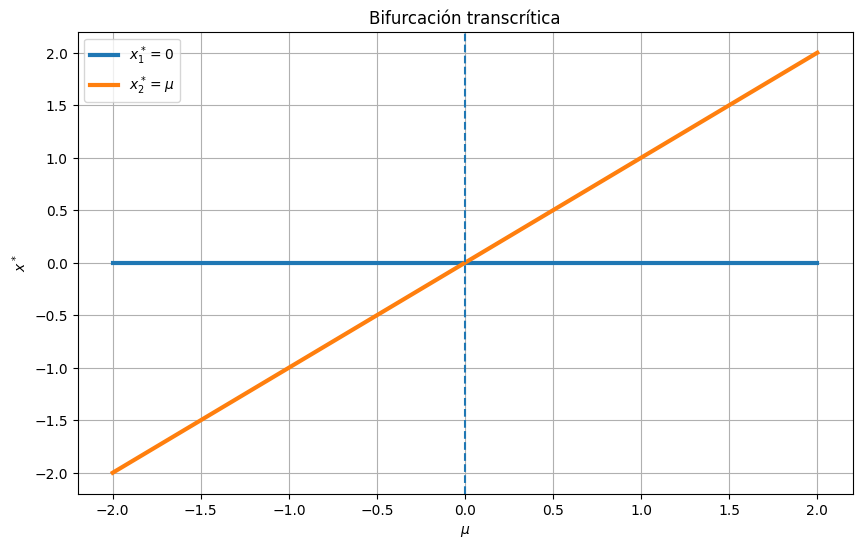

In [4]:
import numpy as np
import matplotlib.pyplot as plt

mu = np.linspace(-2, 2, 1000)

x1 = np.zeros_like(mu)
x2 = mu

plt.figure(figsize=(10, 6))

plt.plot(
    mu,
    x1,
    linewidth=3,
    label=r"$x^*_1=0$"
)

plt.plot(
    mu,
    x2,
    linewidth=3,
    label=r"$x^*_2=\mu$"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(r"$\mu$")
plt.ylabel(r"$x^*$")

plt.title(
    "Bifurcación transcrítica"
)

plt.grid(True)
plt.legend()

plt.show()

# 30. Pitchfork bifurcation

Otra muy importante:

$$
\boxed{
\dot{x}=\mu x-x^3
}
$$

Los equilibrios cumplen:

$$
\mu x-x^3=0.
$$

Factorizamos:

$$
x(\mu-x^2)=0.
$$

Entonces:

$$
x_1=0
$$

y:

$$
x_{2,3}=\pm\sqrt{\mu}.
$$

Para:

$$
\mu<0
$$

solo existe:

$$
x=0.
$$

Para:

$$
\mu>0
$$

aparecen dos nuevos equilibrios.

# 31. Python: Pitchfork

/tmp/ipykernel_40776/1080551842.py:10: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(mu),
/tmp/ipykernel_40776/1080551842.py:16: RuntimeWarning: invalid value encountered in sqrt
  -np.sqrt(mu),


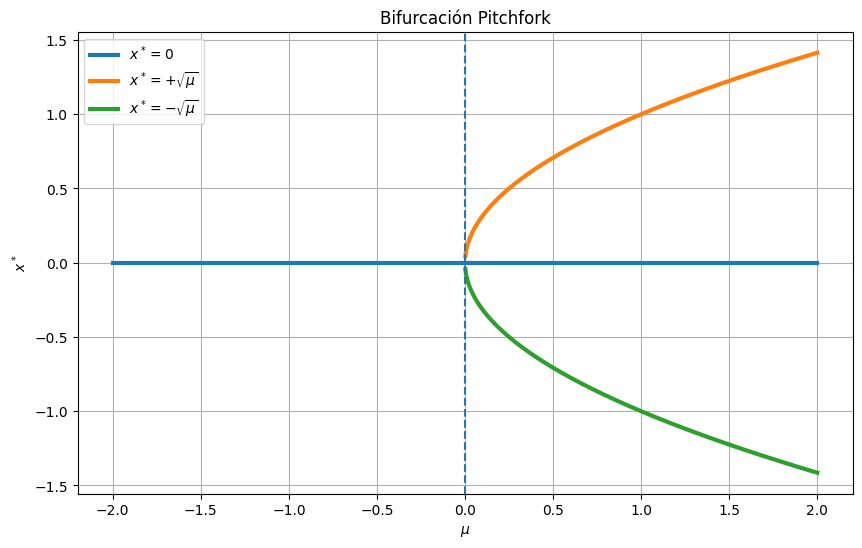

In [5]:
import numpy as np
import matplotlib.pyplot as plt

mu = np.linspace(-2, 2, 1000)

x_zero = np.zeros_like(mu)

x_positive = np.where(
    mu >= 0,
    np.sqrt(mu),
    np.nan
)

x_negative = np.where(
    mu >= 0,
    -np.sqrt(mu),
    np.nan
)

plt.figure(figsize=(10, 6))

plt.plot(
    mu,
    x_zero,
    linewidth=3,
    label=r"$x^*=0$"
)

plt.plot(
    mu,
    x_positive,
    linewidth=3,
    label=r"$x^*=+\sqrt{\mu}$"
)

plt.plot(
    mu,
    x_negative,
    linewidth=3,
    label=r"$x^*=-\sqrt{\mu}$"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(r"$\mu$")
plt.ylabel(r"$x^*$")

plt.title(
    "Bifurcación Pitchfork"
)

plt.grid(True)
plt.legend()

plt.show()

# 32. ¿Por qué las bifurcaciones importan en la vida real?


Porque los parámetros físicos pueden cambiar.

Por ejemplo:

### Ecología

$$
\mu=\text{tasa de crecimiento}
$$

Un cambio puede provocar:

$$
\text{supervivencia}
\rightarrow
\text{extinción}.
$$


### Ingeniería

$$
\mu=\text{velocidad}
$$

Un cambio puede producir:

$$
\text{estabilidad}
\rightarrow
\text{oscilación}.
$$

### Clima

Parámetros físicos pueden cambiar el régimen dinámico.

### Medicina

Un parámetro puede representar una tasa de producción/degradación.

### Economía

Un parámetro puede representar una tasa de inversión, crecimiento o interacción.

### Machine Learning

Cambiar parámetros de un modelo dinámico puede cambiar:

$$
\text{convergencia}
\rightarrow
\text{oscilación}
\rightarrow
\text{inestabilidad}.
$$


# 33. Un ejemplo realista: sistema depredador-presa con crecimiento logístico

Ahora podemos combinar varias ideas.

Supongamos:

$$
\boxed{
\dot{x}
=
rx\left(1-\frac{x}{K}\right)-axy
}
$$

$$
\boxed{
\dot{y}
=
baxy-dy
}
$$

donde:

* $(x)$: presas.
* $(y)$: depredadores.
* $(r)$: crecimiento de presas.
* $(K)$: capacidad de carga.
* $(a)$: tasa de depredación.
* $(b)$: eficiencia de conversión.
* $(d)$: mortalidad.

Esto es mucho más realista que Lotka-Volterra.

# 34. Simularlo

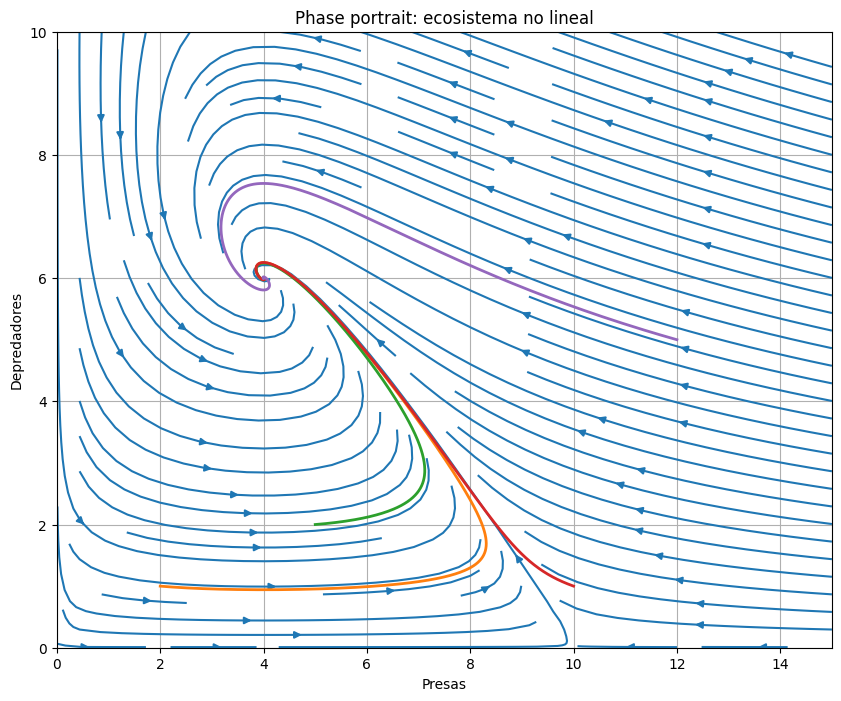

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

r = 1.0
K = 10.0
a = 0.1
b = 0.5
d = 0.2

def ecosystem(t, z):

    x, y = z

    dx = r*x*(1 - x/K) - a*x*y
    dy = b*a*x*y - d*y

    return [dx, dy]

x = np.linspace(0.01, 15, 35)
y = np.linspace(0.01, 10, 35)

X, Y = np.meshgrid(x, y)

U = r*X*(1 - X/K) - a*X*Y
V = b*a*X*Y - d*Y

speed = np.sqrt(U**2 + V**2)

U_norm = U / (speed + 1e-9)
V_norm = V / (speed + 1e-9)

plt.figure(figsize=(10, 8))

plt.streamplot(
    X,
    Y,
    U_norm,
    V_norm,
    density=1.2
)

initial_conditions = [
    [2, 1],
    [5, 2],
    [10, 1],
    [12, 5]
]

for z0 in initial_conditions:

    sol = solve_ivp(
        ecosystem,
        (0, 80),
        z0,
        dense_output=True,
        max_step=0.02
    )

    t = np.linspace(0, 80, 4000)

    trajectory = sol.sol(t)

    plt.plot(
        trajectory[0],
        trajectory[1],
        linewidth=2
    )

plt.xlabel("Presas")
plt.ylabel("Depredadores")

plt.title(
    "Phase portrait: ecosistema no lineal"
)

plt.xlim(0, 15)
plt.ylim(0, 10)

plt.grid(True)

plt.show()

Este ejemplo combina:

$$
\boxed{
\text{ODE}
+
\text{no linealidad}
+
\text{equilibrios}
+
\text{estabilidad}
+
\text{phase portrait}
}
$$

y representa un sistema que se parece mucho más a los que aparecen en aplicaciones reales.

# 35. Conexión directa con SciML

Aquí está la idea que quiero que tengas muy clara.

En matemáticas clásicas escribimos:

$$
\boxed{
\dot{x}=f(x,\mu)
}
$$

Pero en Scientific Machine Learning podemos tener:

$$
\boxed{
\dot{x}=f_\theta(x,\mu)
}
$$

donde $(f_\theta)$ es una red neuronal.

Por ejemplo:

```text
           datos
             │
             ▼
       ┌─────────────┐
       │ Neural Net  │
       │     fθ      │
       └──────┬──────┘
              │
              ▼
       dx/dt = fθ(x)
              │
              ▼
        ODE Solver
              │
              ▼
        x(t)
```

Y después podemos estudiar:

* equilibrios,
* estabilidad,
* atractores,
* phase portraits,
* bifurcaciones,
* caos.

Esto es **mucho más profundo que simplemente ajustar una curva**.

# 36. La conexión con aprendizaje automático

Supongamos que observamos:

$$
x(t_1),x(t_2),...,x(t_n)
$$

pero no conocemos:

$$
f(x).
$$

Podemos proponer:

$$
\boxed{
\dot{x}=NN_\theta(x)
}
$$

y entrenar la red para que:

$$
x_\theta(t_i)
\approx
x_i.
$$

Después de aprender $(NN_\theta)$, podemos preguntarnos:

> ¿Qué equilibrios tiene la dinámica aprendida?

Eso significa resolver:

$$
NN_\theta(x^*)=0.
$$

Y podemos calcular:

$$
J=
\frac{\partial NN_\theta}{\partial x}
$$

para estudiar estabilidad.

Así que conceptos que estás aprendiendo ahora:

$$
\boxed{
\text{equilibrio}
\rightarrow
\text{Jacobiano}
\rightarrow
\text{eigenvalues}
\rightarrow
\text{estabilidad}
}
$$

son directamente reutilizables en **Neural ODEs y SciML**.

# 37. Mapa mental

Quédate con esta estructura:

```text
                    SISTEMA DINÁMICO
                          │
                          ▼
                  dx/dt = f(x, μ)
                          │
          ┌───────────────┼────────────────┐
          │               │                │
          ▼               ▼                ▼
     EQUILIBRIOS      TRAYECTORIAS      PARÁMETROS
       f(x*)=0             │                │
          │                │                │
          ▼                ▼                ▼
     JACOBIANO        PHASE PORTRAIT    BIFURCACIONES
          │                │                │
          ▼                ▼                ▼
     EIGENVALUES       ATRACTORES       CAMBIO
          │                              CUALITATIVO
          ▼
     ESTABILIDAD
```

| **Inicio**         | **atrás 1**                          | **Siguiente 3**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./5_1_ODE.ipynb) | [⏩](./5_3_Sistemas_lineales.ipynb) |